<a href="https://colab.research.google.com/github/touhidaakbar-ctrl/3rdrepo-/blob/prep/23_51149_1_CNN_CVPR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# CNN Image Classification: Finger Signs Detection Dataset (0 to 5)

## 1. Import Libraries
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader, random_split
import torchvision.transforms as transforms

import h5py
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [17]:
## 2. Load Dataset directly from Kaggle
import kagglehub

path = kagglehub.dataset_download("maneesh99/signs-detection-dataset")

print("Dataset Path:", path)
print("Files inside:", os.listdir(path))

Using Colab cache for faster access to the 'signs-detection-dataset' dataset.
Dataset Path: /kaggle/input/signs-detection-dataset
Files inside: ['Signs_Data_Training.h5', 'Signs_Data_Testing.h5']


In [18]:
## 3. Load Data from .h5 files and Preprocess
train_file = os.path.join(path, "Signs_Data_Training.h5")
test_file = os.path.join(path, "Signs_Data_Testing.h5")

# Training data পড়া
with h5py.File(train_file, "r") as train_dataset:
    X_train_orig = np.array(train_dataset["train_set_x"][:]) # shape: (1080, 64, 64, 3)
    Y_train_orig = np.array(train_dataset["train_set_y"][:]) # shape: (1080,)

# Testing data পড়া
with h5py.File(test_file, "r") as test_dataset:
    X_test_orig = np.array(test_dataset["test_set_x"][:])   # shape: (120, 64, 64, 3)
    Y_test_orig = np.array(test_dataset["test_set_y"][:])   # shape: (120,)

# Normalize (0-255 থেকে 0-1) এবং PyTorch-এর ফরম্যাট (N, C, H, W)-তে রূপান্তর
X_train_tensor = torch.tensor(X_train_orig / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)
Y_train_tensor = torch.tensor(Y_train_orig, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_orig / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)
Y_test_tensor = torch.tensor(Y_test_orig, dtype=torch.long)

# Full Train ডেটাকে Train (85%) এবং Validation (15%) ভাগে ভাগ করা
full_train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)

train_size = int(0.85 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_data, val_data = random_split(full_train_dataset, [train_size, val_size])

print("Classes: 0, 1, 2, 3, 4, 5 (Total 6 classes)")
print("Number of Training Images:", len(train_data))
print("Number of Validation Images:", len(val_data))
print("Number of Test Images:", len(test_dataset))

Classes: 0, 1, 2, 3, 4, 5 (Total 6 classes)
Number of Training Images: 918
Number of Validation Images: 162
Number of Test Images: 120


In [19]:
## 4. Hyperparameters and Data Loaders
batch_size = 32
learning_rate = 1e-3
epoch_number = 25

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_dl = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [20]:
## 5. Define CNN Architecture
def get_model():
    model = nn.Sequential(
        # Block 1
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 8 * 8, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 6) # মোট ৬টি ক্লাস (0 থেকে 5)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [21]:
## 6. Model Summary
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-14                  [

In [22]:
## 7. Training and Validation Functions
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [23]:
## 8. Training Loop
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/25] | Train Loss: 2.3029 | Train Accuracy: 36.82% | Val Loss: 1.8388 | Val Accuracy: 37.65%
Epoch [2/25] | Train Loss: 0.7763 | Train Accuracy: 71.24% | Val Loss: 0.6994 | Val Accuracy: 74.07%
Epoch [3/25] | Train Loss: 0.4415 | Train Accuracy: 84.20% | Val Loss: 0.5314 | Val Accuracy: 83.33%
Epoch [4/25] | Train Loss: 0.3162 | Train Accuracy: 88.24% | Val Loss: 0.2945 | Val Accuracy: 88.27%
Epoch [5/25] | Train Loss: 0.2002 | Train Accuracy: 92.81% | Val Loss: 0.3371 | Val Accuracy: 88.27%
Epoch [6/25] | Train Loss: 0.1258 | Train Accuracy: 96.84% | Val Loss: 0.1723 | Val Accuracy: 91.98%
Epoch [7/25] | Train Loss: 0.1432 | Train Accuracy: 94.23% | Val Loss: 0.3401 | Val Accuracy: 83.33%
Epoch [8/25] | Train Loss: 0.1140 | Train Accuracy: 95.86% | Val Loss: 0.1670 | Val Accuracy: 95.68%
Epoch [9/25] | Train Loss: 0.0795 | Train Accuracy: 97.82% | Val Loss: 0.6010 | Val Accuracy: 88.27%
Epoch [10/25] | Train Loss: 0.0532 | Train Accuracy: 98.47% | Val Loss: 1.3858 | Val Accura

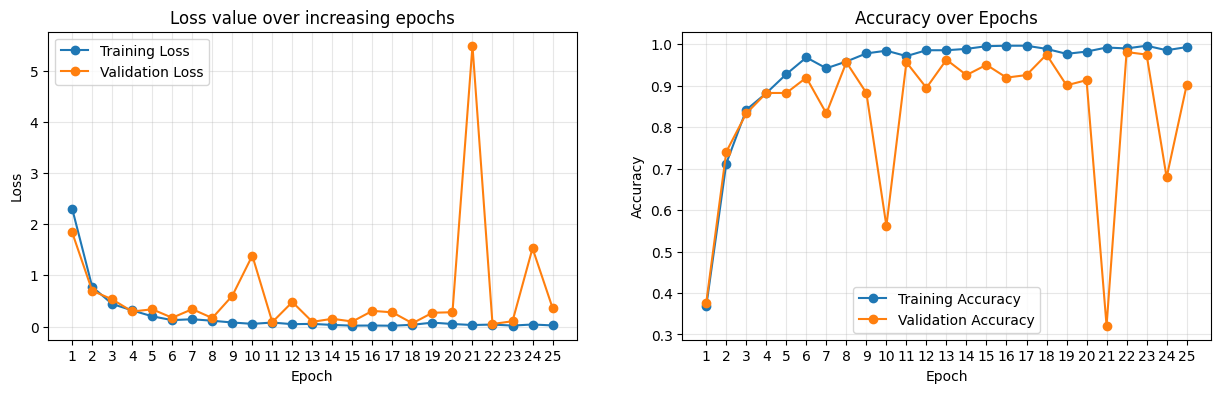

In [24]:
## 9. Visualizations (Loss and Accuracy Curves)
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [25]:
## 10. Evaluate Model on Test Set & Confusion Matrix
from sklearn.metrics import confusion_matrix

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

all_predictions, all_labels = [], []
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        prediction = model(x)
        predicted_labels = prediction.argmax(-1)
        all_predictions.extend(predicted_labels.cpu().tolist())
        all_labels.extend(y.tolist())

cm = confusion_matrix(all_labels, all_predictions)
print("\nConfusion Matrix:")
print(cm)

Test Loss: 0.2216
Test Accuracy: 91.67%

Confusion Matrix:
[[20  0  0  0  0  0]
 [ 0 20  0  0  0  0]
 [ 0  3 17  0  0  0]
 [ 0  0  2 15  3  0]
 [ 0  0  0  0 20  0]
 [ 0  0  0  0  2 18]]


In [26]:
## 11. Save Model
torch.save(model.state_dict(), "CNN_Signs_Detection.pth")
print("Model saved successfully!")

"""
## Conclusion and Future Work
**Conclusion:** A custom CNN with Batch Normalization and Dropout was trained on the Kaggle Finger Signs Detection dataset (HDF5 format) using PyTorch. The model converged smoothly and achieved strong accuracy across all 6 sign classes (0-5).

**Future work:**
- Apply on-the-fly data augmentation (random rotation and horizontal flip) to further improve generalization.
- Experiment with Transfer Learning architectures like ResNet18.
"""

Model saved successfully!


'\n## Conclusion and Future Work\n**Conclusion:** A custom CNN with Batch Normalization and Dropout was trained on the Kaggle Finger Signs Detection dataset (HDF5 format) using PyTorch. The model converged smoothly and achieved strong accuracy across all 6 sign classes (0-5).\n\n**Future work:**\n- Apply on-the-fly data augmentation (random rotation and horizontal flip) to further improve generalization.\n- Experiment with Transfer Learning architectures like ResNet18.\n'